In [237]:
import pandas as pd
import numpy as np
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, SimpleRNN, Input

In [238]:
df=pd.read_csv('/content/spam.csv', encoding="latin1")

In [239]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [240]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [241]:
df.shape

(5572, 5)

In [242]:
df.describe()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2


In [245]:
df.isnull().sum()

,0
v1,0
v2,0


The original dataset contains 5,572 SMS messages with labels identifying ham and spam. The `v1` column represents the message category, while `v2` contains the actual SMS text. Three unnecessary columns contain mostly missing values, so they are removed during data cleaning.


In [244]:
df=df.drop(columns=['Unnamed: 2','Unnamed: 3', 'Unnamed: 4'])

In [246]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [249]:
df.duplicated().sum()

np.int64(0)

In [248]:
df = df.drop_duplicates()

1. Unnecessary columns and duplicate records were removed.
2. Cleaning was verified by checking missing values and duplicates again.

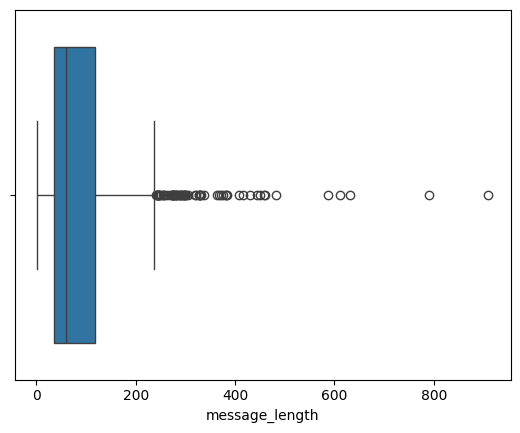

In [250]:
df['message_length'] = df['v2'].apply(len)

sns.boxplot(x=df['message_length'])
plt.show()

In [251]:
Q1 = df['message_length'].quantile(0.25)
Q3 = df['message_length'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['message_length'] < lower) |
              (df['message_length'] > upper)]

print("Total Outliers:", len(outliers))

Total Outliers: 66


In [231]:
# The 66 message-length outliers are retained deliberately.
# Long messages may be valid SMS messages and may contain useful spam information.

print("Rows retained after outlier analysis:", len(df))

Rows retained after outlier analysis: 5169


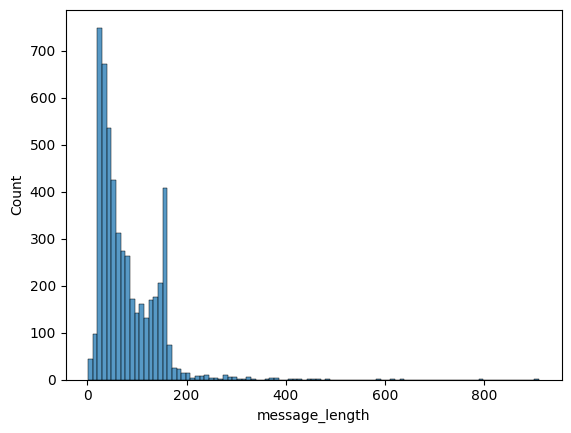

In [214]:
sns.histplot(df['message_length'])
plt.show()

In [232]:
df['word_count'] = df['v2'].apply(lambda x: len(x.split()))

df[['message_length', 'word_count']].head()

,message_length,word_count
0,111,20
1,29,6
2,155,28
3,49,11
4,61,13


1. message_length measures the number of characters in each SMS.
2. word_count measures the number of words in each SMS.
3. Both features help compare spam and ham message patterns.

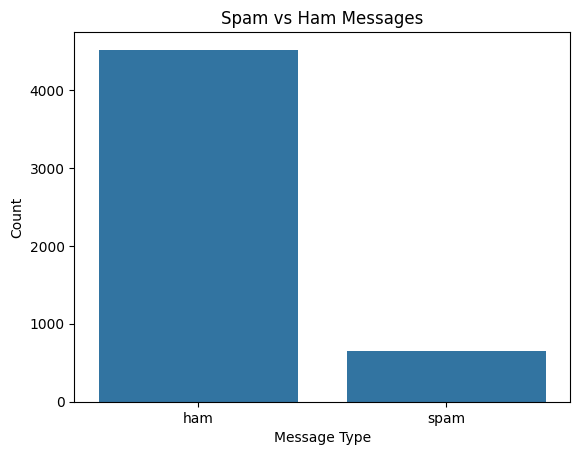

In [233]:
sns.countplot(x='v1', data=df)
plt.title('Spam vs Ham Messages')
plt.xlabel('Message Type')
plt.ylabel('Count')
plt.show()

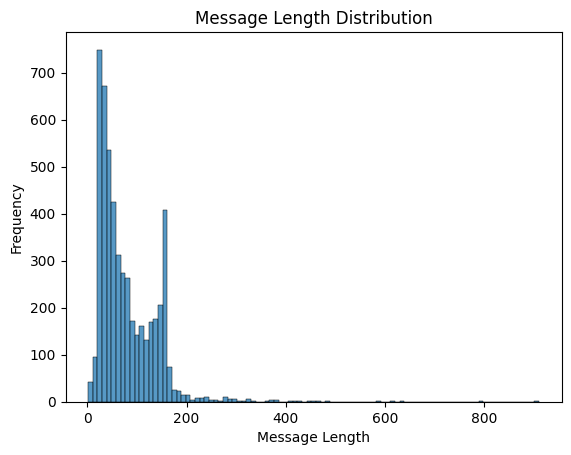

In [234]:
sns.histplot(df['message_length'])
plt.title('Message Length Distribution')
plt.xlabel('Message Length')
plt.ylabel('Frequency')
plt.show()

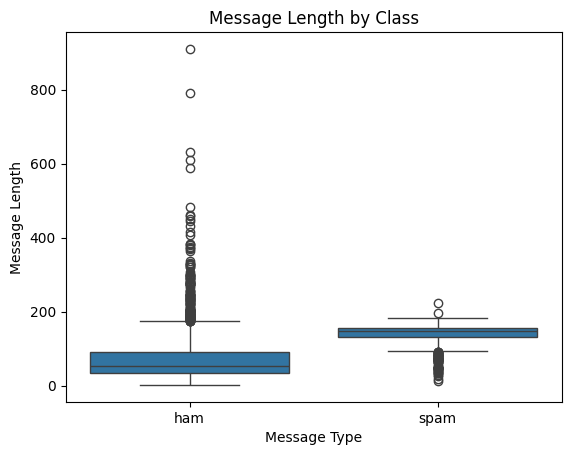

In [235]:
sns.boxplot(x='v1', y='message_length', data=df)
plt.title('Message Length by Class')
plt.xlabel('Message Type')
plt.ylabel('Message Length')
plt.show()

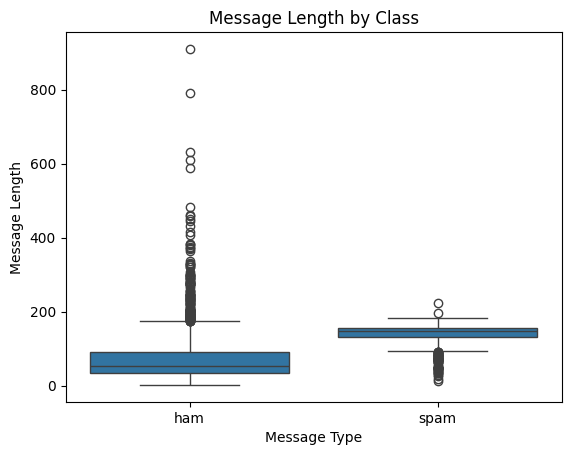

In [236]:
sns.boxplot(x='v1', y='message_length', data=df)
plt.title('Message Length by Class')
plt.xlabel('Message Type')
plt.ylabel('Message Length')
plt.show()

1. The original dataset contains 5,572 SMS messages categorized into ham and spam.
2. Three unnecessary columns were removed because they contained mostly missing values.
3. Duplicate messages were identified during data cleaning to improve dataset quality.
4. The class distribution shows that ham messages are more common than spam messages, indicating an imbalanced dataset.
5. The outlier analysis identified 66 unusual message lengths, and these messages were retained because they may contain useful information for spam classification.


In [217]:
x= df["v2"]
y= df["v1"]

In [218]:
df['v1'].value_counts()

,count
v1,
ham,4516
spam,653


In [219]:
le=LabelEncoder()
y=le.fit_transform(y)

In [220]:
np.unique(y)

array([0, 1])

In [221]:
x_train,x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42,stratify=y)

In [222]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [223]:
tokenizer= Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(x_train)

x_train_seq = tokenizer.texts_to_sequences(x_train)
x_test_seq = tokenizer.texts_to_sequences(x_test)

In [224]:
x_train_seq[0]

[282, 24, 45, 61, 4, 470, 108, 3488, 8, 3489, 181]

In [225]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [226]:
x_train_pad = pad_sequences(x_train_seq, maxlen=50, padding='post', truncating='post')
x_test_pad = pad_sequences(x_test_seq, maxlen=50, padding='post', truncating='post')

In [227]:
model=Sequential([
    Input(shape=(50,)),
    Embedding(input_dim=5000, output_dim=32),
    SimpleRNN(32),
    Dense(1, activation='sigmoid')
])

In [228]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [229]:
history= model.fit(x_train_pad,y_train, epochs=5, validation_split=0.2)

Epoch 1/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8706 - loss: 0.4100 - val_accuracy: 0.8791 - val_loss: 0.3692
Epoch 2/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8724 - loss: 0.3841 - val_accuracy: 0.8791 - val_loss: 0.3692
Epoch 3/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8724 - loss: 0.3827 - val_accuracy: 0.8791 - val_loss: 0.3713
Epoch 4/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8724 - loss: 0.3841 - val_accuracy: 0.8791 - val_loss: 0.3691
Epoch 5/5
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8724 - loss: 0.3825 - val_accuracy: 0.8791 - val_loss: 0.3700


In [230]:
loss, accuracy= model.evaluate(x_test_pad, y_test)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8733 - loss: 0.3823


1. A Simple RNN is used for text classification because it processes words in a sequence and learns patterns from the text.
2. We use tokenization to convert text into numbers and padding to make all sequences the same length.
3. The Embedding layer converts words into vectors, and the SimpleRNN layer learns patterns from the sequence.
4. A Simple RNN struggles with long sequences because of the vanishing gradient problem, where gradients become very small during backpropagation through time.
5. As a result, the model struggles to remember information from earlier words, making it difficult to learn long-term dependencies.